# HOTEL BOOKING ANALYSIS

## 1. PROJECT INTRODUCTION

## 2. DATA CLEANING AND PREPROCESSING

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")


#Load Dataset

df = pd.read_csv("hotel_bookings.csv.zip")

print("Dataset loaded successfully!")

# Display first 5 rows
df.head()

# Display last 5 rows
df.tail()

# Number of rows and columns
df.shape

# Column names
df.columns

# Information about columns and data types
df.info()

# Statistical summary
df.describe(include='all')

# Check missing values in each column

df.isnull().sum().sort_values(ascending=False)

# Missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_table[missing_table['Missing Values'] > 0]

# Step 3: Handle Missing Values

df['company'] = df['company'].fillna(0)

df['agent'] = df['agent'].fillna(0)

df['country'] = df['country'].fillna('Unknown')

df['children'] = df['children'].fillna(0)

# Verify missing values
df.isnull().sum().sum()

# Count duplicate records

df.duplicated().sum()

# Remove duplicate records

df = df.drop_duplicates()

# Check updated dataset size

df.shape

# Step 4: Correct Data Types

df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

df['children'] = df['children'].astype(int)

df['agent'] = df['agent'].astype(int)

df['company'] = df['company'].astype(int)

# Check updated data types

df.dtypes

# Step 5: Create Derived Columns

# Total guests
df['total_guests'] = (
    df['adults'] + df['children'] + df['babies']
)

# Total nights
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

# Create arrival date
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d',
    errors='coerce'
)

# Display new columns
df[['total_guests', 'total_nights', 'arrival_date']].head()

# Check negative ADR values
(df['adr'] < 0).sum()

# Check zero guest records
(df['total_guests'] == 0).sum()

# Check zero-night bookings
(df['total_nights'] == 0).sum()

# Check unusually high ADR
df['adr'].describe()

# Final dataset information

print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Records:")
display(df.head())

# Save preprocessed dataset

df.to_csv("hotel_bookings_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")





Libraries imported successfully!
Dataset loaded successfully!
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                     

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests,total_nights,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0,0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2,0,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0,0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2,0,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0,0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,0,0,Transient,98.0,0,1,Check-Out,2015-07-03,2,2,2015-07-01


Cleaned dataset saved successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("hotel_bookings_cleaned.csv")
df['arrival_date'] = pd.to_datetime(df['arrival_date'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests,total_nights,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0,Transient,0.0,0,0,Check-Out,2015-07-01,2,0,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0,Transient,0.0,0,0,Check-Out,2015-07-01,2,0,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0,Transient,98.0,0,1,Check-Out,2015-07-03,2,2,2015-07-01


In [4]:
print("Dataset Shape:", df.shape)
display(df.describe())
display(df.describe(include='all'))

Dataset Shape: (87396, 35)


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,total_guests,total_nights,arrival_date
count,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,...,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396
mean,0.274898,79.891368,2016.210296,26.838334,15.815541,1.005263,2.625395,1.875795,0.138633,0.010824,...,0.271603,81.004657,11.016809,0.749565,106.337246,0.084226,0.698567,2.025253,3.630658,2016-09-15 00:20:26.857064
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000,0.000000,0.000000,2015-07-01 00:00:00
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,9.000000,0.000000,0.000000,72.000000,0.000000,0.000000,2.000000,2.000000,2016-04-01 00:00:00
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,...,0.000000,9.000000,0.000000,0.000000,98.100000,0.000000,0.000000,2.000000,3.000000,2016-09-20 00:00:00
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,...,0.000000,234.000000,0.000000,0.000000,134.000000,0.000000,1.000000,2.000000,5.000000,2017-04-01 00:00:00
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,...,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000,55.000000,69.000000,2017-08-31 00:00:00
std,0.446466,86.052325,0.686102,13.674572,8.835146,1.031921,2.053584,0.626500,0.455871,0.113597,...,0.727245,109.945638,54.047484,10.015731,55.013953,0.281533,0.831946,0.794319,2.763449,NaN


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests,total_nights,arrival_date
count,87396,87396.000000,87396.000000,87396.000000,87396,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,...,87396.000000,87396,87396.000000,87396.000000,87396.000000,87396,87396,87396.000000,87396.000000,87396
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,NaN,4,NaN,NaN,NaN,3,926,NaN,NaN,NaN
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,NaN,Transient,NaN,NaN,NaN,Check-Out,2016-02-14,NaN,NaN,NaN
freq,53428,NaN,NaN,NaN,11257,NaN,NaN,NaN,NaN,NaN,...,NaN,71986,NaN,NaN,NaN,63371,211,NaN,NaN,NaN
mean,NaN,0.274898,79.891368,2016.210296,NaN,26.838334,15.815541,1.005263,2.625395,1.875795,...,0.749565,NaN,106.337246,0.084226,0.698567,NaN,NaN,2.025253,3.630658,2016-09-15 00:20:26.857064
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,2015-07-01 00:00:00
25%,NaN,0.000000,11.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,0.000000,NaN,72.000000,0.000000,0.000000,NaN,NaN,2.000000,2.000000,2016-04-01 00:00:00
50%,NaN,0.000000,49.000000,2016.000000,NaN,27.000000,16.000000,1.000000,2.000000,2.000000,...,0.000000,NaN,98.100000,0.000000,0.000000,NaN,NaN,2.000000,3.000000,2016-09-20 00:00:00
75%,NaN,1.000000,125.000000,2017.000000,NaN,37.000000,23.000000,2.000000,4.000000,2.000000,...,0.000000,NaN,134.000000,0.000000,1.000000,NaN,NaN,2.000000,5.000000,2017-04-01 00:00:00
max,NaN,1.000000,737.000000,2017.000000,NaN,53.000000,31.000000,19.000000,50.000000,55.000000,...,391.000000,NaN,5400.000000,8.000000,5.000000,NaN,NaN,55.000000,69.000000,2017-08-31 00:00:00


## 3.DATA VISUALIZATION

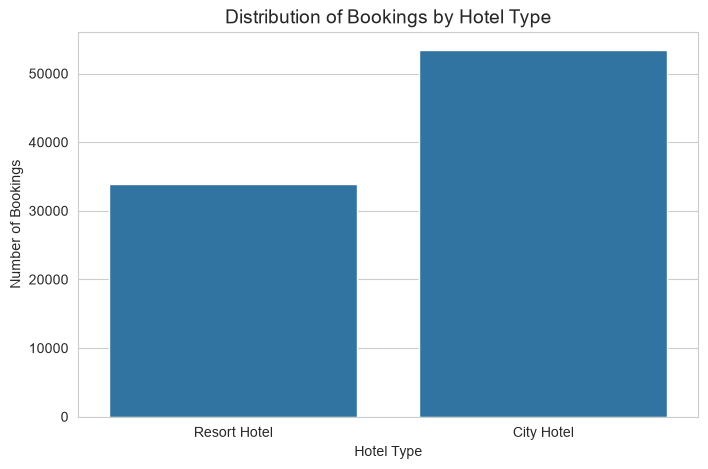

In [6]:
#chart 1: Booking Distribution by Hotel Type

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='hotel')
plt.title('Distribution of Bookings by Hotel Type',
          fontsize=14)
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.show()

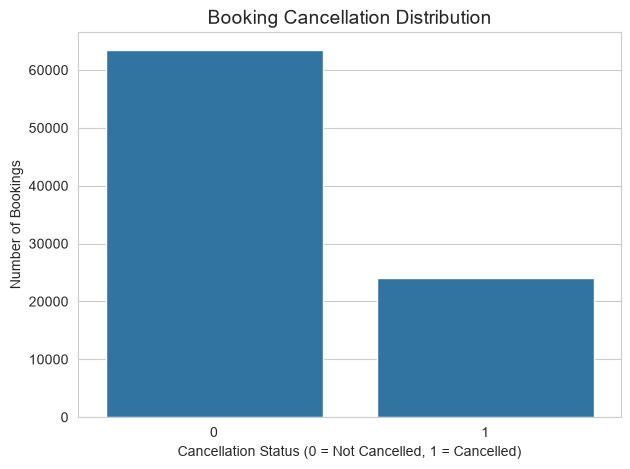

In [7]:

# Chart2: Booking Cancellation Distribution

plt.figure(figsize=(7,5))
sns.countplot(data=df, x='is_canceled')
plt.title('Booking Cancellation Distribution',
          fontsize=14)
plt.xlabel('Cancellation Status (0 = Not Cancelled, 1 = Cancelled)')
plt.ylabel('Number of Bookings')
plt.show()

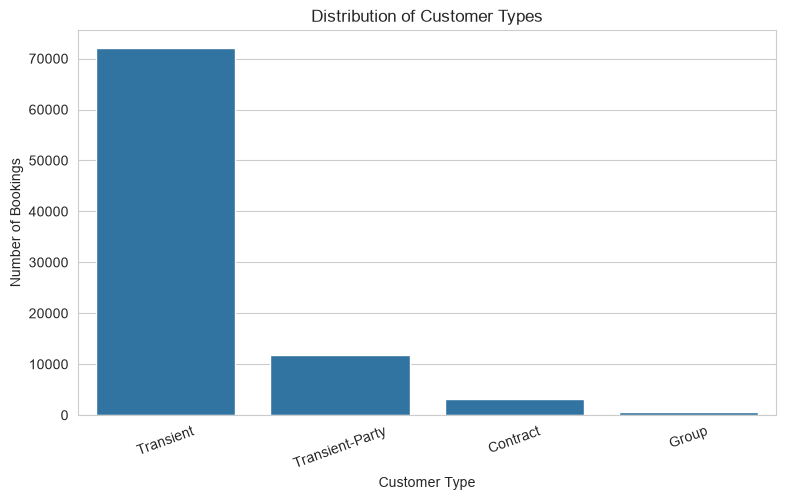

In [8]:

# Chart 3: Customer Type Distribution

plt.figure(figsize=(9,5))
sns.countplot(data=df, x='customer_type',
              order=df['customer_type'].value_counts().index)
plt.title('Distribution of Customer Types')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=20)
plt.show()

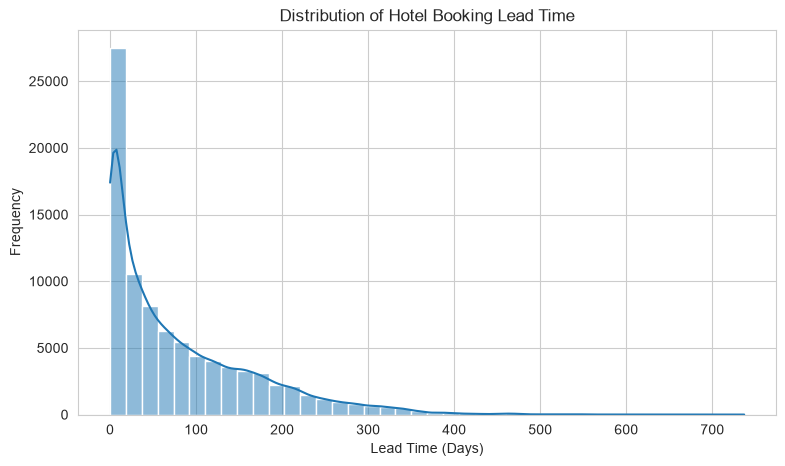

In [9]:

# Chart4: Lead Time Distribution

plt.figure(figsize=(9,5))
sns.histplot(data=df, x='lead_time',
             bins=40, kde=True)
plt.title('Distribution of Hotel Booking Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Frequency')
plt.show()

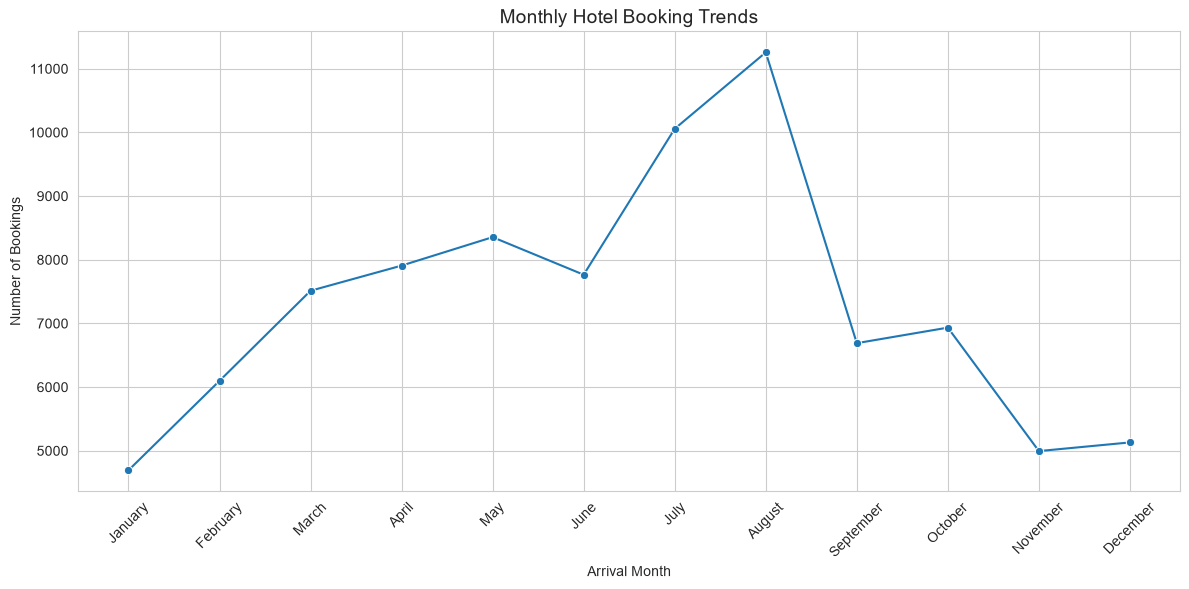

In [11]:
# Chart 5: Monthly Booking Trends

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = (
    df.groupby('arrival_date_month')
    .size()
    .reindex(month_order)
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_bookings.index,
    y=monthly_bookings.values,
    marker='o'
)

plt.title('Monthly Hotel Booking Trends', fontsize=14)
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('hotel_bookings_cleaned.csv')

print(df.shape)

(87396, 35)


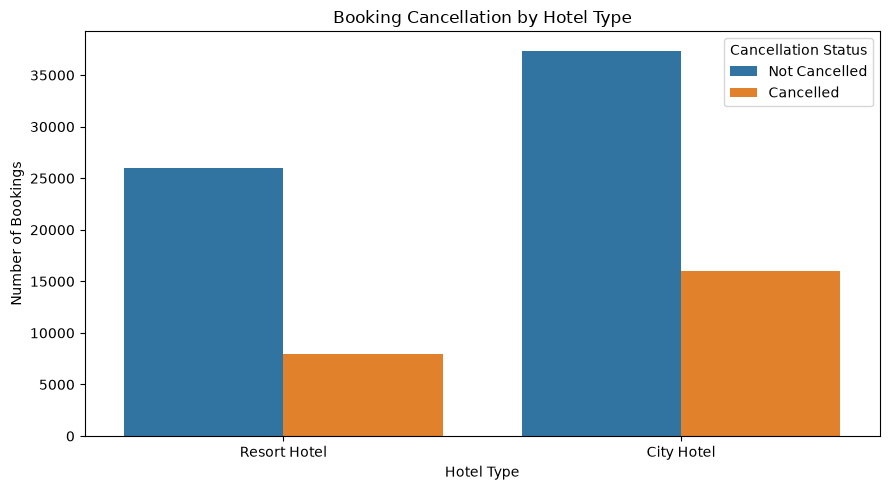

In [6]:
# Chart 6: Booking Cancellation by Hotel Type

df['cancellation_status'] = df['is_canceled'].map({
    0: 'Not Cancelled',
    1: 'Cancelled'
})

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='hotel', hue='cancellation_status')

plt.title('Booking Cancellation by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.legend(title='Cancellation Status')
plt.tight_layout()
plt.show()

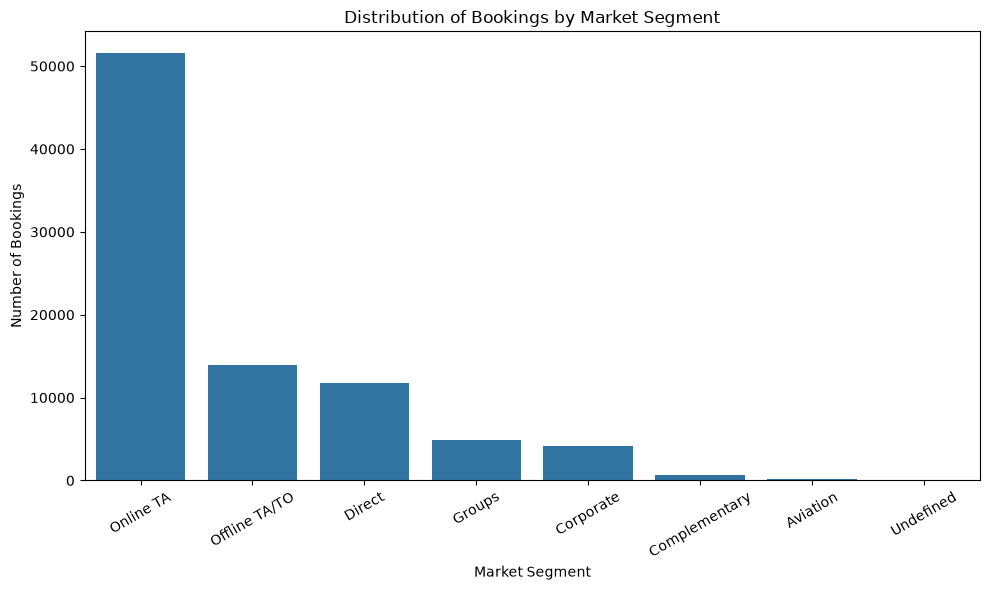

In [8]:
# Chart 7: Booking Distribution by Market Segment

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='market_segment',
    order=df['market_segment'].value_counts().index
)

plt.title('Distribution of Bookings by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

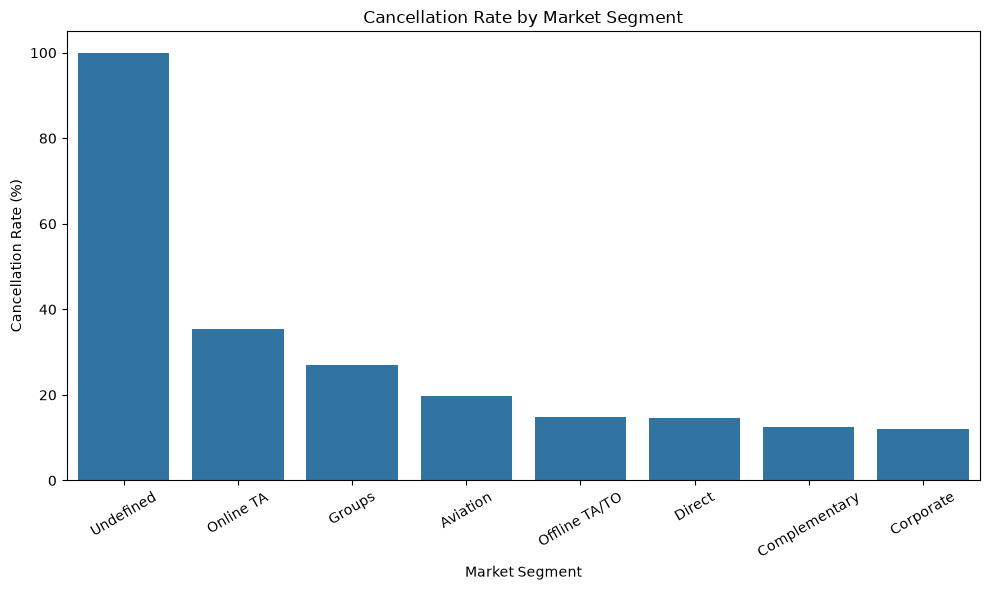

In [9]:
# Chart 8: Cancellation Rate by Market Segment

cancel_rate = (
    df.groupby('market_segment')['is_canceled']
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=cancel_rate.index,
    y=cancel_rate.values
)

plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

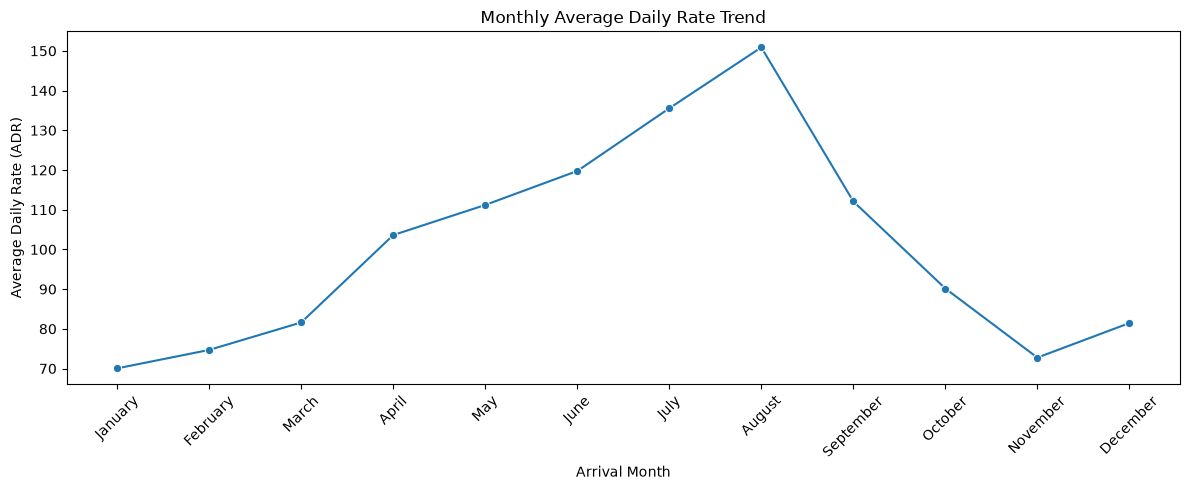

In [10]:

# Chart 9: Monthly Average ADR Trend

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_adr = (
    df.groupby('arrival_date_month')['adr']
    .mean()
    .reindex(month_order)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_adr.index,
    y=monthly_adr.values,
    marker='o'
)

plt.title('Monthly Average Daily Rate Trend')
plt.xlabel('Arrival Month')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

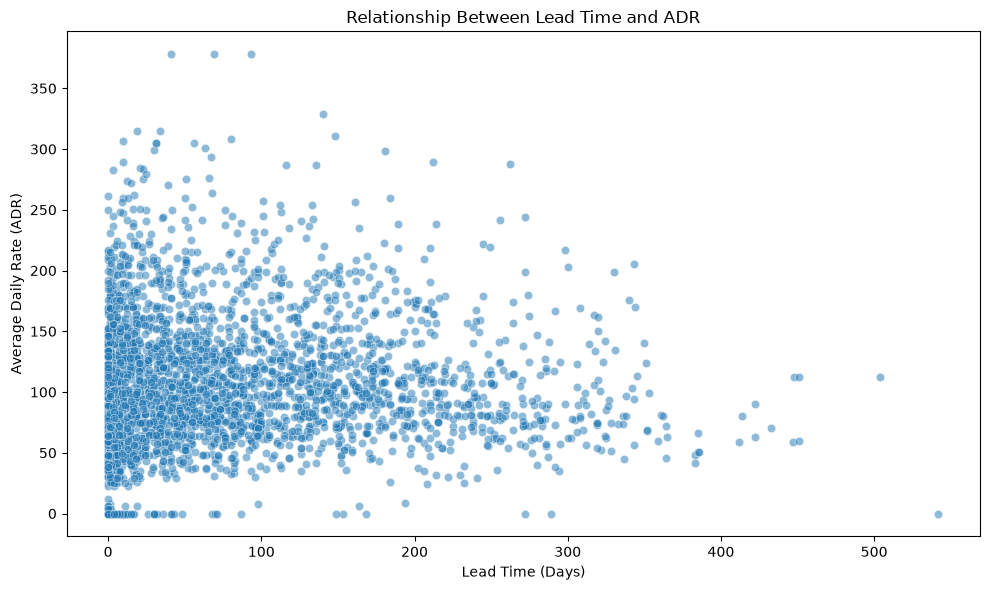

In [11]:

# Chart 10: Lead Time vs ADR

# Select a sample to make the scatter plot easier to read
sample_df = df.sample(
    n=min(3000, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x='lead_time',
    y='adr',
    alpha=0.5
)

plt.title('Relationship Between Lead Time and ADR')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')

plt.tight_layout()
plt.show()

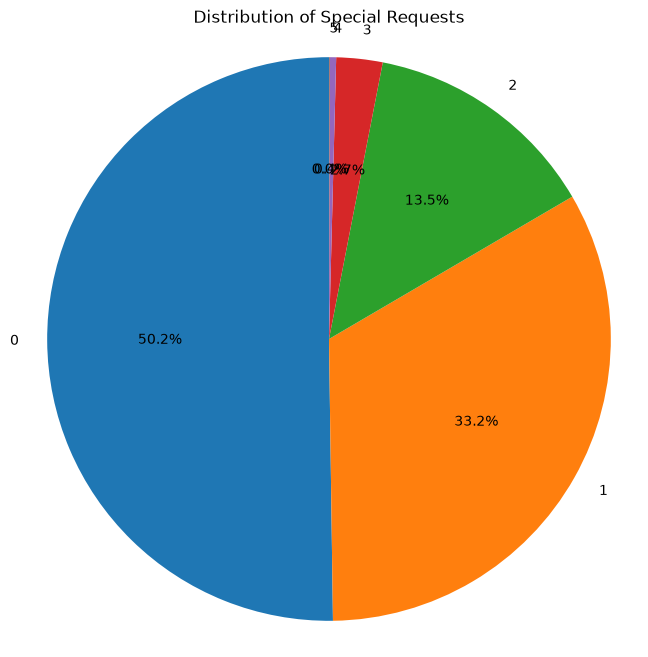

In [12]:

# Chart 11: Distribution of Special Requests

request_counts = df['total_of_special_requests'].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    request_counts,
    labels=request_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Special Requests')
plt.axis('equal')
plt.show()

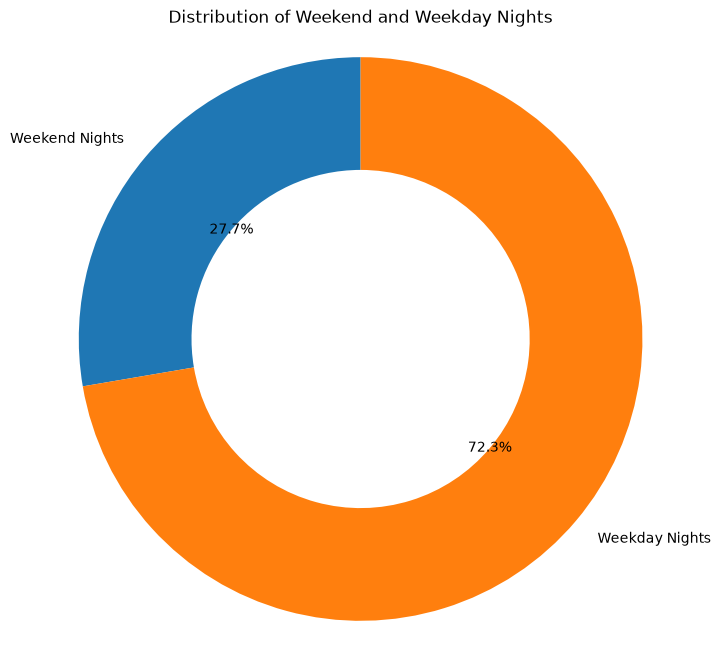

In [13]:

# Chart 12: Weekend Nights vs Weekday Nights

night_counts = [
    df['stays_in_weekend_nights'].sum(),
    df['stays_in_week_nights'].sum()
]

labels = ['Weekend Nights', 'Weekday Nights']

plt.figure(figsize=(8, 8))

plt.pie(
    night_counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Distribution of Weekend and Weekday Nights')
plt.axis('equal')
plt.show()

***Overall Conclusion***

The Hotel Booking Analysis project provided valuable insights into hotel booking patterns, customer behaviour, cancellation trends, pricing strategies, and guest preferences. Using Python libraries such as Pandas, Matplotlib, and Seaborn, the project involved data cleaning, preprocessing, exploratory data analysis, and the creation of 12 different visualizations.

The analysis helped identify important trends and relationships within the dataset, including booking distribution, customer types, lead time, monthly demand, cancellation rates, average daily rates, and guest stay patterns. It also highlighted challenges such as missing values, duplicate records, and data preprocessing.

Based on these findings, recommendations were developed to improve reservation management, optimize room pricing, plan resources, reduce cancellations, and enhance customer satisfaction.

Overall, this project demonstrated how raw data can be transformed into meaningful insights that support better business decision-making. It also strengthened my practical skills in Python, data analysis, data visualization, and interpreting real-world business data.


***Key Findings***

Based on the dataset analysis and visualizations:

1. **Hotel Booking Preferences**: The analysis compares booking volumes between City Hotels and Resort Hotels to understand customer preferences.
2. **Cancellation Behaviour:** The cancellation rate is approximately 27.49%, showing that cancellations are an important factor in hotel reservation management.
3. **Customer Segmentation:** The analysis identifies four customer types: Contract, Group, Transient, and Transient-party.
4. **Booking Lead Time:** The average booking lead time is approximately 79.89 days, indicating that customers make reservations at different intervals before arrival.
5. **Monthly Booking Trends:** Monthly analysis helps identify changes in booking demand throughout the year.
6. **Room Pricing:** ADR analysis helps compare room rates and understand pricing variations between hotel categories.
7. **Customer Requirements:** Special requests provide information about additional services and arrangements customers may need.
8. **Stay Preferences:** Comparing weekday and weekend nights helps understand guest stay patterns.